# HealthAI Suite: Phase 1 (clean version)
**Objectives:** O1 length-of-stay regression, O2 diabetes / heart-disease classification, O3 patient clustering, all on the MIMIC-III demo.

*Contains information from MIMIC-III Clinical Database Demo, made available under the Open Database License (ODbL).*

**How to read this notebook (7 sections, run top to bottom):**
1. Setup: every decision lives in one config cell
2. Load the 8 tables and check their quality
3. Build the master table (one row per admission)
4. EDA: what does the data look like?
5. Features, preprocessing and the patient-grouped split (stated before any model)
6. O1, O2, O3: models and results
7. Summary for Bala

**Honest framing:** 129 admissions from 100 patients is tiny, and the demo patients were selected from people who eventually died. This is a methodology demo, not a clinical claim.

## 1. Setup

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import drive

drive.mount("/content/drive")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# ================= CONFIG: every decision lives here =================
SEED = 42                                       # same seed everywhere (configs/config.yaml)
DATA = Path("/content/drive/MyDrive/HealthAISuite/Datasets/mimic-demo-1.4")
OUT = Path("/content/drive/MyDrive/HealthAISuite/Processed")

TABLES = ["PATIENTS", "ADMISSIONS", "ICUSTAYS", "DIAGNOSES_ICD",
          "D_ICD_DIAGNOSES", "LABEVENTS", "D_LABITEMS", "PRESCRIPTIONS"]
EXPECTED_SHAPES = {"PATIENTS": (100, 8), "ADMISSIONS": (129, 19), "ICUSTAYS": (136, 12),
                   "DIAGNOSES_ICD": (1761, 5), "D_ICD_DIAGNOSES": (14567, 4),
                   "LABEVENTS": (76074, 9), "D_LABITEMS": (753, 6), "PRESCRIPTIONS": (10398, 19)}
STR_COLS = {"DIAGNOSES_ICD": {"ICD9_CODE": str}, "D_ICD_DIAGNOSES": {"ICD9_CODE": str}}  # keep leading zeros

AGE_CAP = 90                                    # MIMIC shifts ages > 89 to ~300
ICU_WINDOW_H = 24
LAB_WINDOW_H = (-6, 24)                         # hours from admission
LAB_MIN_COVERAGE = 0.80                         # keep labs present in >= 80% of admissions
UNIT_ALIASES = {"seconds": "sec", "uu/ml": "uiu/ml"}   # same unit, different spelling

ADMISSION_TYPE_MAP = {"EMERGENCY": "EMERGENCY", "ELECTIVE": "NON_EMERGENCY", "URGENT": "NON_EMERGENCY"}
INSURANCE_MAP = {"Medicare": "MEDICARE", "Private": "PRIVATE", "Medicaid": "MEDICAID_GOV", "Government": "MEDICAID_GOV"}
LOCATION_MAP = {"EMERGENCY ROOM ADMIT": "ER",
                "TRANSFER FROM HOSP/EXTRAM": "TRANSFER_IN", "TRANSFER FROM SKILLED NUR": "TRANSFER_IN",
                "CLINIC REFERRAL/PREMATURE": "REFERRAL", "PHYS REFERRAL/NORMAL DELI": "REFERRAL"}
DIABETES_CATS = ["249", "250"]                  # ICD-9 3-character categories (labels only)
HEART_CATS = ["410", "411", "412", "413", "414", "428"]
LABEL_DRUGS = ("insulin|metformin|glipizide|glyburide|glimepiride|pioglitazone|sitagliptin"
               "|nitroglycerin|isosorbide|clopidogrel|digoxin|carvedilol")   # draft list, confirm with Bala

# Columns that must never be features (they leak the answer)
FORBIDDEN = {"dischtime", "deathtime", "discharge_location", "hospital_expire_flag", "diagnosis", "los"}
EXPECTED = {"rows": 129, "diabetes": 48, "heart_disease": 52, "icu_by_24h": 112}   # numbers found in the quality checks

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Load the tables and check quality
Only 8 of the 26 MIMIC tables are in scope. We load them, check each shape against the expected one, then look at nulls, duplicates and key uniqueness.

In [2]:
def load_tables():
    """Load the 8 in-scope tables with lowercase columns and check their shapes."""
    raw = {}
    for name in TABLES:
        df = pd.read_csv(DATA / f"{name}.csv", low_memory=False, dtype=STR_COLS.get(name))
        df.columns = df.columns.str.lower()
        assert df.shape == EXPECTED_SHAPES[name], f"{name}: got {df.shape}"
        raw[name] = df
    return raw


def quality_report(raw):
    """One row per table: size, share of null cells, duplicate rows, and the emptiest column."""
    rows = []
    for name, df in raw.items():
        null_share = df.isna().mean()
        rows.append({"table": name, "rows": len(df), "cols": df.shape[1],
                     "null cells %": round(null_share.mean() * 100, 1),
                     "duplicate rows": int(df.duplicated().sum()),
                     "emptiest column": null_share.idxmax(), "its null %": round(null_share.max() * 100, 1)})
    return pd.DataFrame(rows)


raw = load_tables()
display(quality_report(raw))

# Key checks: is one row really one admission / patient / ICU stay?
adm_ids = set(raw["ADMISSIONS"]["hadm_id"])
print("ADMISSIONS hadm_id unique:", raw["ADMISSIONS"]["hadm_id"].is_unique)
print("PATIENTS subject_id unique:", raw["PATIENTS"]["subject_id"].is_unique)
print("ICUSTAYS icustay_id unique:", raw["ICUSTAYS"]["icustay_id"].is_unique)
print("admissions whose patient is missing from PATIENTS:",
      int((~raw["ADMISSIONS"]["subject_id"].isin(raw["PATIENTS"]["subject_id"])).sum()))
print("DIAGNOSES_ICD duplicate (hadm_id, icd9_code):", int(raw["DIAGNOSES_ICD"].duplicated(["hadm_id", "icd9_code"]).sum()))
print("LABEVENTS rows with no hadm_id (outpatient, dropped later):", int(raw["LABEVENTS"]["hadm_id"].isna().sum()))

,table,rows,cols,null cells %,duplicate rows,emptiest column,its null %
0,PATIENTS,100,8,6.6,0,dod_hosp,30.0
1,ADMISSIONS,129,19,9.3,0,deathtime,69.0
2,ICUSTAYS,136,12,0.0,0,row_id,0.0
3,DIAGNOSES_ICD,1761,5,0.0,0,row_id,0.0
4,D_ICD_DIAGNOSES,14567,4,0.0,0,row_id,0.0
5,LABEVENTS,76074,9,11.5,0,flag,60.9
6,D_LABITEMS,753,6,3.7,0,loinc_code,22.3
7,PRESCRIPTIONS,10398,19,7.0,0,drug_name_poe,44.5


ADMISSIONS hadm_id unique: True
PATIENTS subject_id unique: True
ICUSTAYS icustay_id unique: True
admissions whose patient is missing from PATIENTS: 0
DIAGNOSES_ICD duplicate (hadm_id, icd9_code): 0
LABEVENTS rows with no hadm_id (outpatient, dropped later): 14262


### What the quality checks decided (from the original notebook)
| Table | Keep / build | Drop |
| --- | --- | --- |
| ADMISSIONS | `los_days` (target, `dischtime - admittime`); admission type, insurance, ethnicity, marital status (grouped); admission location | dischtime, deathtime, discharge_location, hospital_expire_flag, diagnosis |
| PATIENTS | gender; age (year difference, capped at 90) plus a "was shifted" flag | dob, dod and related date columns |
| ICUSTAYS | "ICU by hour 24" flag; first care unit within 24 h | outtime, los, last_careunit, number of stays |
| DIAGNOSES_ICD | diabetes and heart-disease **labels only** | every code, flag or count as a feature |
| LABEVENTS | window -6 h to 24 h; mean per lab; labs present in >= 80% of admissions | rows without hadm_id; non-numeric results; mixed units |
| PRESCRIPTIONS | count of orders and unique drugs on or before admission day (MAIN orders, label-defining drugs excluded) | drug-level columns |

**Why a window?** Lab values and orders after hour 24 are not known at prediction time, so using them would leak the future.

## 3. Build the master table
One function per source table, then `build_master` runs them all and checks the result (grain, nulls, no leakage columns, label counts).

In [3]:
def group_ethnicity(s):
    """Keyword rules; anything else -> OTHER_UNKNOWN."""
    s = str(s).upper()
    for key, grp in [("WHITE", "WHITE"), ("HISPANIC", "HISPANIC"), ("LATINO", "HISPANIC"),
                     ("BLACK", "BLACK"), ("ASIAN", "ASIAN")]:
        if key in s:
            return grp
    return "OTHER_UNKNOWN"


def build_base(raw):
    """ADMISSIONS + PATIENTS -> one row per admission: target los_days, age, grouped categories."""
    adm, pat = raw["ADMISSIONS"].copy(), raw["PATIENTS"].copy()
    for c in ["admittime", "dischtime"]:
        adm[c] = pd.to_datetime(adm[c])
    pat["dob"] = pd.to_datetime(pat["dob"])
    adm["los_days"] = (adm["dischtime"] - adm["admittime"]).dt.total_seconds() / 86400   # NOT ICUSTAYS.los
    adm["admission_type_grp"] = adm["admission_type"].map(ADMISSION_TYPE_MAP)
    adm["insurance_grp"] = adm["insurance"].map(INSURANCE_MAP)
    adm["ethnicity_grp"] = adm["ethnicity"].map(group_ethnicity)
    adm["marital_grp"] = (adm["marital_status"].replace({"UNKNOWN (DEFAULT)": None}).fillna("UNKNOWN")
                          .replace({"SEPARATED": "DIVORCED_SEPARATED", "DIVORCED": "DIVORCED_SEPARATED"}))
    adm["admission_location_grp"] = adm["admission_location"].map(LOCATION_MAP)
    adm = adm.merge(pat[["subject_id", "gender", "dob"]], on="subject_id", how="left")
    age_raw = adm["admittime"].dt.year - adm["dob"].dt.year        # year difference: safe for shifted dob
    adm["age_was_shifted"] = (age_raw > 89).astype(int)
    adm["age"] = age_raw.clip(upper=AGE_CAP)
    cols = ["hadm_id", "subject_id", "los_days", "age", "age_was_shifted", "gender", "admission_type_grp",
            "insurance_grp", "ethnicity_grp", "marital_grp", "admission_location_grp"]
    return adm[cols].copy(), adm[["hadm_id", "admittime"]].copy()


def add_icu_features(base, raw, adm_times):
    """First ICU stay per admission; only what is known by hour 24."""
    icu = raw["ICUSTAYS"].copy()
    icu["intime"] = pd.to_datetime(icu["intime"])
    first = (icu.sort_values("intime").groupby("hadm_id").first().reset_index()
                .merge(adm_times, on="hadm_id", how="left"))
    hrs = (first["intime"] - first["admittime"]).dt.total_seconds() / 3600
    first["icu_by_24h"] = (hrs.clip(lower=0) <= ICU_WINDOW_H).astype(int)
    first["first_careunit_24h"] = np.where(first["icu_by_24h"] == 1, first["first_careunit"], "NONE_BY_24H")
    return base.merge(first[["hadm_id", "icu_by_24h", "first_careunit_24h"]], on="hadm_id", how="left")


def add_labels(base, raw):
    """O2 labels from ICD-9 category prefixes. Labels only, never features."""
    dx = raw["DIAGNOSES_ICD"].copy()
    cat3 = dx["icd9_code"].astype(str).str.strip().str[:3]
    dx["diabetes"], dx["heart_disease"] = cat3.isin(DIABETES_CATS), cat3.isin(HEART_CATS)
    labels = dx.groupby("hadm_id")[["diabetes", "heart_disease"]].any().astype(int).reset_index()
    out = base.merge(labels, on="hadm_id", how="left")
    out[["diabetes", "heart_disease"]] = out[["diabetes", "heart_disease"]].fillna(0).astype(int)
    return out


def build_lab_features(base, raw, adm_times):
    """Mean per item in the lab window; numeric, single-unit items present in >= 80% of admissions."""
    lab = raw["LABEVENTS"].copy()
    lab["charttime"] = pd.to_datetime(lab["charttime"])
    lab = lab.dropna(subset=["hadm_id", "valuenum"]).copy()          # outpatient and non-numeric rows
    lab["hadm_id"] = lab["hadm_id"].astype("int64")
    lab = lab.merge(adm_times, on="hadm_id", how="inner")
    lab["hrs"] = (lab["charttime"] - lab["admittime"]).dt.total_seconds() / 3600
    W = lab[(lab["hrs"] >= LAB_WINDOW_H[0]) & (lab["hrs"] <= LAB_WINDOW_H[1])].copy()
    names = raw["D_LABITEMS"].set_index("itemid")["label"]

    W["unit"] = W["valueuom"].str.strip().str.lower().replace(UNIT_ALIASES)
    n_units = W.groupby("itemid")["unit"].nunique()
    mixed = n_units[n_units > 1].index                               # genuinely different units
    dominant = W[W["itemid"].isin(mixed)].groupby("itemid")["unit"].agg(lambda s: s.value_counts().idxmax())
    W = W[~W["itemid"].isin(mixed) | (W["unit"] == W["itemid"].map(dominant))]

    cov = W.groupby("itemid")["hadm_id"].nunique() / base["hadm_id"].nunique()
    keep = cov[cov >= LAB_MIN_COVERAGE].index
    assert len(keep) > 0 and not set(keep) & set(mixed), "lab selection problem"
    wide = W[W["itemid"].isin(keep)].groupby(["hadm_id", "itemid"])["valuenum"].mean().unstack()
    wide.columns = [f"lab_{i}_{re.sub(r'[^a-z0-9]+', '_', names[i].lower()).strip('_')}" for i in wide.columns]
    return wide.reindex(base["hadm_id"]).rename_axis("hadm_id").reset_index()   # missing stays NaN


def build_rx_features(base, raw, adm_times):
    """Counts of MAIN orders on/before the admission date, excluding label-defining drugs. None -> 0."""
    rx = raw["PRESCRIPTIONS"].copy()
    rx["startdate"] = pd.to_datetime(rx["startdate"])
    rx = rx.merge(adm_times, on="hadm_id", how="inner")
    rx["day_offset"] = (rx["startdate"] - rx["admittime"].dt.normalize()).dt.days
    E = rx[(rx["day_offset"] <= 0) & (rx["drug_type"] == "MAIN")].copy()
    E["drug_norm"] = E["drug"].fillna("").str.lower().str.strip()
    E = E[~E["drug_norm"].str.contains(LABEL_DRUGS)]
    return (E.groupby("hadm_id").agg(n_orders_24h=("drug", "size"), n_unique_drugs_24h=("drug_norm", "nunique"))
              .reindex(pd.Index(base["hadm_id"], name="hadm_id"), fill_value=0).reset_index())


def build_master(raw):
    """Run every step and check the result."""
    base, adm_times = build_base(raw)
    base = add_labels(add_icu_features(base, raw, adm_times), raw)
    master = (base.merge(build_lab_features(base, raw, adm_times), on="hadm_id", how="left")
                  .merge(build_rx_features(base, raw, adm_times), on="hadm_id", how="left"))
    assert len(master) == EXPECTED["rows"] and master["hadm_id"].is_unique, "grain broken"
    assert master[[c for c in master.columns if not c.startswith("lab_")]].notna().all().all(), "nulls outside labs"
    assert not FORBIDDEN & set(master.columns), "leakage column present"
    assert master["diabetes"].sum() == EXPECTED["diabetes"] and master["heart_disease"].sum() == EXPECTED["heart_disease"]
    assert master["icu_by_24h"].sum() == EXPECTED["icu_by_24h"]
    return master


master = build_master(raw)
print("master:", master.shape, "| lab columns:", sum(c.startswith("lab_") for c in master.columns),
      "| lab missing share: %.1f %%" % (master.filter(like="lab_").isna().mean().mean() * 100))

# Optional safety net: if an earlier master.csv exists on Drive, prove this version matches it
if (OUT / "master.csv").exists():
    pd.testing.assert_frame_equal(master.reset_index(drop=True), pd.read_csv(OUT / "master.csv"), check_dtype=False)
    print("identical to the saved master.csv from the original notebook")

OUT.mkdir(parents=True, exist_ok=True)
master.to_csv(OUT / "master.csv", index=False)       # stays on Drive, never committed

master: (129, 40) | lab columns: 23 | lab missing share: 2.2 %
identical to the saved master.csv from the original notebook


## 4. EDA
Understand the data, do not select features. Nothing here fits a model.

LOS (days): mean 9.33 | median 6.63 | std 12.72 | skew 6.15
log(1 + LOS) skew: 0.14  -> model on the log scale, report error in days
longest stay: 124 days | stays > 30 days: 5
MAE of always predicting the median (reference only): 5.95 days


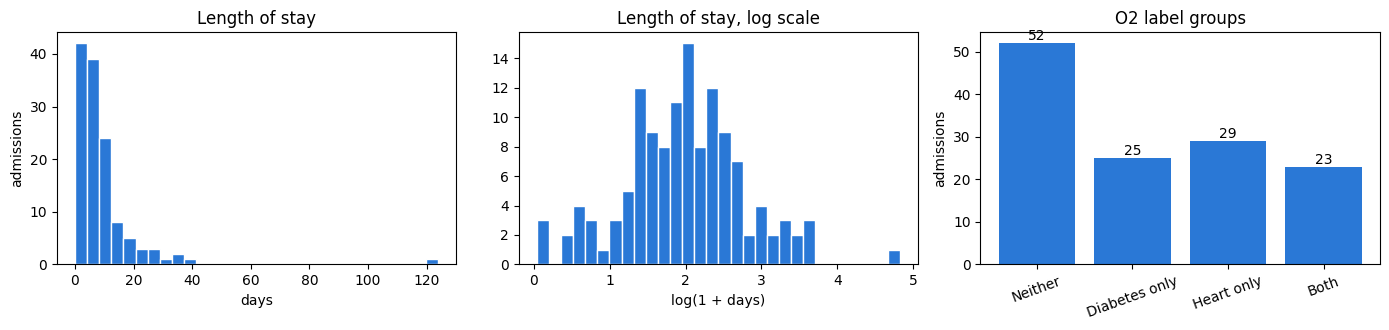

In [4]:
los = master["los_days"]
print("LOS (days): mean %.2f | median %.2f | std %.2f | skew %.2f" % (los.mean(), los.median(), los.std(), los.skew()))
print("log(1 + LOS) skew: %.2f  -> model on the log scale, report error in days" % np.log1p(los).skew())
print("longest stay: %.0f days | stays > 30 days: %d" % (los.max(), (los > 30).sum()))
print("MAE of always predicting the median (reference only): %.2f days" % np.abs(los - los.median()).mean())

fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
ax[0].hist(los, bins=30, color="#2a78d6", edgecolor="white")
ax[0].set(title="Length of stay", xlabel="days", ylabel="admissions")
ax[1].hist(np.log1p(los), bins=30, color="#2a78d6", edgecolor="white")
ax[1].set(title="Length of stay, log scale", xlabel="log(1 + days)")

# O2 label groups: diabetes and heart disease overlap, so show the four combinations
group = np.select([(master["diabetes"] == 1) & (master["heart_disease"] == 1),
                   master["diabetes"] == 1, master["heart_disease"] == 1],
                  ["Both", "Diabetes only", "Heart only"], "Neither")
order = ["Neither", "Diabetes only", "Heart only", "Both"]
counts = pd.Series(group).value_counts().reindex(order)
bars = ax[2].bar(order, counts.values, color="#2a78d6")
ax[2].bar_label(bars)
ax[2].set(title="O2 label groups", ylabel="admissions")
ax[2].tick_params(axis="x", labelrotation=20)
plt.tight_layout(); plt.show()

In [5]:
# Repeat patients: the one patient with the most admissions can dominate small data
top = master["subject_id"].value_counts().idxmax()
is_top = master["subject_id"] == top
display(master.assign(group=np.where(is_top, f"top patient ({is_top.sum()} admissions)", "all others"))
        .groupby("group").agg(admissions=("hadm_id", "size"), los_median=("los_days", "median"),
                              diabetes_rate=("diabetes", "mean"), heart_rate=("heart_disease", "mean"),
                              age_median=("age", "median")).round(2))

# Group differences (descriptive only). Cells with fewer than 20 admissions are too small to interpret.
master["age_band"] = pd.cut(master["age"], bins=[0, 64, 79, 90], labels=["<65", "65-79", "80+"])
for by in ["gender", "age_band"]:
    display(master.groupby(by, observed=True).agg(
        admissions=("hadm_id", "size"), patients=("subject_id", "nunique"), los_median=("los_days", "median"),
        diabetes_rate=("diabetes", "mean"), heart_rate=("heart_disease", "mean")).round(2))

,admissions,los_median,diabetes_rate,heart_rate,age_median
group,,,,,
all others,114,6.82,0.30,0.46,76.0
top patient (15 admissions),15,4.08,0.93,0.00,65.0


,admissions,patients,los_median,diabetes_rate,heart_rate
gender,,,,,
F,59,55,6.83,0.32,0.49
M,70,45,5.97,0.41,0.33


,admissions,patients,los_median,diabetes_rate,heart_rate
age_band,,,,,
<65,36,25,7.72,0.36,0.11
65-79,46,33,6.82,0.39,0.39
80+,47,43,5.07,0.36,0.64


In [6]:
# Lab pairs that say nearly the same thing (|Spearman| >= 0.85): used to prune features in section 5
labs = master.filter(like="lab_")
corr = labs.corr(method="spearman")
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("rho").reset_index()
pairs = pairs[pairs["rho"].abs() >= 0.85].sort_values("rho", key=abs, ascending=False)
pairs["level_0"] = pairs["level_0"].str.split("_", n=2).str[2]
pairs["level_1"] = pairs["level_1"].str.split("_", n=2).str[2]
display(pairs.rename(columns={"level_0": "lab A", "level_1": "lab B"}).round(2).reset_index(drop=True))
print("n_orders_24h vs n_unique_drugs_24h correlation:",
      round(master[["n_orders_24h", "n_unique_drugs_24h"]].corr(method="spearman").iloc[0, 1], 2))

,lab A,lab B,rho
0,inr_pt,pt,0.99
1,hematocrit,hemoglobin,0.94
2,mch,mcv,0.88
3,hematocrit,red_blood_cells,0.87


n_orders_24h vs n_unique_drugs_24h correlation: 0.98


**EDA findings**
- **LOS:** very right-skewed (skew 6.2; log scale 0.1). One stay of about 124 days dominates RMSE, so MAE is the headline metric.
- **Labels:** neither 52, diabetes only 25, heart only 29, both 23.
- **One patient has 15 admissions** (about 14 with diabetes). They supply 29% of diabetes-positive admissions but are 1 of 31 diabetes-positive patients, so we weight rows by 1 / admissions-per-patient and re-check without them.
- **Age:** heart-disease rate rises sharply with age (0.11 -> 0.39 -> 0.64); diabetes is flat (about 0.36-0.39). So an age-only baseline matters for heart disease.
- **Drop (correlated pairs):** PT (~INR), hematocrit (~hemoglobin), MCH (~MCV), and keep `n_unique_drugs_24h` only (0.98 with order count). Chosen without using the target.

## 5. Features, preprocessing and the split (stated before any model)

| | Task | Metrics | Baselines | Models |
| --- | --- | --- | --- | --- |
| O1 | Regression on `los_days` (model log(1 + days), report days) | MAE (primary), RMSE, R2 | Training-fold median | Ridge, Random Forest |
| O2 | Two binary classifiers: diabetes, heart disease | F1, ROC-AUC, accuracy | Majority class; age-only logistic | Logistic regression, XGBoost (MLP not run) |
| O3 | Clustering on the same features | Silhouette | none | k-means (HDBSCAN not run) |

- **Split:** 5-fold `StratifiedGroupKFold` on `subject_id`, seed 42. No patient is in both train and test.
- **Preprocessing:** median imputation, scaling and one-hot encoding sit inside a `Pipeline`, so they are fitted on training folds only.
- **Patient weights:** each admission is weighted 1 / (admissions of that patient), so one patient counts once. Reported next to plain scores.

In [7]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# --- Feature list (decisions from section 4) ---
master["icu_unit_grp"] = master["first_careunit_24h"].replace(
    {"SICU": "SURGICAL_ICU", "TSICU": "SURGICAL_ICU", "CSRU": "SURGICAL_ICU"})
DROP_LABS = ["lab_51274_pt", "lab_51221_hematocrit", "lab_51248_mch"]       # near-duplicates (|rho| >= 0.85)
LAB_COLS = [c for c in master.columns if c.startswith("lab_") and c not in DROP_LABS]
NUM = ["age"] + LAB_COLS + ["n_unique_drugs_24h"]
BIN = ["age_was_shifted", "icu_by_24h"]
CAT = ["gender", "admission_type_grp", "admission_location_grp", "insurance_grp", "icu_unit_grp"]
FEATURES = NUM + BIN + CAT
assert len(LAB_COLS) == 20, len(LAB_COLS)
assert not {"los_days", "diabetes", "heart_disease", "subject_id", "hadm_id"} & set(FEATURES)
assert not FORBIDDEN & set(FEATURES), "leakage column in features"

# --- Preprocessing: fitted on training folds only because it lives inside each model's Pipeline ---
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUM),
    ("bin", "passthrough", BIN),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
])

# --- One split for every model, grouped by patient, balanced by label combination ---
master["label_group"] = np.select(
    [(master["diabetes"] == 1) & (master["heart_disease"] == 1), master["diabetes"] == 1, master["heart_disease"] == 1],
    ["both", "diabetes_only", "heart_only"], "neither")
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv = list(sgkf.split(master, master["label_group"], groups=master["subject_id"]))

X_all = master[FEATURES]
y = master["los_days"]
groups = master["subject_id"]
w = 1 / master.groupby("subject_id")["hadm_id"].transform("size")       # each patient counts once

rows = []
for k, (tr, te) in enumerate(cv):
    assert set(groups.iloc[tr]).isdisjoint(groups.iloc[te]), "patient in both train and test"
    t = master.iloc[te]
    rows.append({"fold": k, "test_admissions": len(te), "test_patients": t["subject_id"].nunique(),
                 "diabetes_pos": int(t["diabetes"].sum()), "heart_pos": int(t["heart_disease"].sum()),
                 "has_top_patient": bool((t["subject_id"] == top).any())})
display(pd.DataFrame(rows))
print("features:", len(FEATURES), "| numeric", len(NUM), "| binary", len(BIN), "| categorical", len(CAT))

,fold,test_admissions,test_patients,diabetes_pos,heart_pos,has_top_patient
0,0,18,18,8,8,False
1,1,25,21,4,7,False
2,2,39,20,22,11,True
3,3,24,21,9,10,False
4,4,23,20,5,16,False


features: 29 | numeric 22 | binary 2 | categorical 5


## 6a. O1: length-of-stay regression
Success target: MAE below the baseline. The baseline always predicts the training-fold median.

In [8]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error


def cv_mae(model, X):
    """MAE in days for each fold: plain and patient-weighted."""
    plain, weighted = [], []
    for tr, te in cv:
        model.fit(X.iloc[tr], y.iloc[tr])
        p = model.predict(X.iloc[te])
        plain.append(mean_absolute_error(y.iloc[te], p))
        weighted.append(mean_absolute_error(y.iloc[te], p, sample_weight=w.iloc[te]))
    return np.array(plain), np.array(weighted)


def make_model(est):
    """Preprocessing + model, trained on log(1 + days); predictions come back in days."""
    pipe = Pipeline([("prep", preprocess), ("model", est)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)


def mean_sd(a):
    return f"{np.mean(a):.2f} +/- {np.std(a, ddof=1):.2f}"


res = {"median baseline": cv_mae(DummyRegressor(strategy="median"), X_all),
       "Ridge (alpha=1)": cv_mae(make_model(Ridge(alpha=1.0)), X_all),
       "Random Forest": cv_mae(make_model(RandomForestRegressor(
           n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1)), X_all)}

base_plain = res["median baseline"][0]
display(pd.DataFrame([{"model": name, "MAE plain": mean_sd(p), "MAE patient-weighted": mean_sd(wt),
                       "folds beating baseline": "-" if name == "median baseline" else f"{int((p < base_plain).sum())}/5"}
                      for name, (p, wt) in res.items()]))

,model,MAE plain,MAE patient-weighted,folds beating baseline
0,median baseline,6.05 +/- 2.42,6.28 +/- 2.30,-
1,Ridge (alpha=1),6.96 +/- 1.97,7.11 +/- 1.83,1/5
2,Random Forest,6.00 +/- 2.29,6.19 +/- 2.24,3/5


In [9]:
# Tune Ridge's alpha with nested CV: the inner grouped CV picks alpha inside each training fold only
from sklearn.model_selection import GridSearchCV, GroupKFold

ridge_search = GridSearchCV(make_model(Ridge()),
                            param_grid={"regressor__model__alpha": [1, 10, 100, 1000, 10000]},
                            scoring="neg_mean_absolute_error", cv=GroupKFold(n_splits=3))
plain, weighted, chosen = [], [], []
for tr, te in cv:
    ridge_search.fit(X_all.iloc[tr], y.iloc[tr], groups=groups.iloc[tr])
    p = ridge_search.predict(X_all.iloc[te])
    plain.append(mean_absolute_error(y.iloc[te], p))
    weighted.append(mean_absolute_error(y.iloc[te], p, sample_weight=w.iloc[te]))
    chosen.append(ridge_search.best_params_["regressor__model__alpha"])
print("Ridge tuned (nested): plain %s | weighted %s | folds beating baseline: %d/5"
      % (mean_sd(plain), mean_sd(weighted), int((np.array(plain) < base_plain).sum())))
print("alpha chosen per fold:", chosen, "(large alpha = the model ignores most features)")

Ridge tuned (nested): plain 6.01 +/- 2.37 | weighted 6.22 +/- 2.28 | folds beating baseline: 4/5
alpha chosen per fold: [1000, 1000, 10000, 1000, 100] (large alpha = the model ignores most features)


In [10]:
# Pooled out-of-fold predictions: every admission is predicted by a model that never saw its patient
from sklearn.metrics import mean_squared_error, r2_score


def oof_predict(model, X, tuned=False):
    pred = np.zeros(len(X))
    for tr, te in cv:
        model.fit(X.iloc[tr], y.iloc[tr], **({"groups": groups.iloc[tr]} if tuned else {}))
        pred[te] = model.predict(X.iloc[te])
    return pred


preds = {"median baseline": oof_predict(DummyRegressor(strategy="median"), X_all),
         "Ridge (tuned)": oof_predict(ridge_search, X_all, tuned=True),
         "Random Forest": oof_predict(make_model(RandomForestRegressor(
             n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1)), X_all)}

longest = int(np.argmax(y.values))
rows = []
for scope, mask in [("all 129", np.ones(len(y), dtype=bool)),
                    ("without the longest stay", np.arange(len(y)) != longest)]:
    for name, pred in preds.items():
        yt, yp = y.values[mask], pred[mask]
        rows.append({"scope": scope, "model": name, "MAE": round(mean_absolute_error(yt, yp), 2),
                     "RMSE": round(float(np.sqrt(mean_squared_error(yt, yp))), 2), "R2": round(r2_score(yt, yp), 3)})
display(pd.DataFrame(rows))

,scope,model,MAE,RMSE,R2
0,all 129,median baseline,6.03,13.04,-0.058
1,all 129,Ridge (tuned),6.00,13.05,-0.061
2,all 129,Random Forest,6.04,12.98,-0.049
3,without the longest stay,median baseline,5.16,7.93,-0.080
4,without the longest stay,Ridge (tuned),5.12,7.95,-0.084
5,without the longest stay,Random Forest,5.17,7.86,-0.059


**O1 reading:** no model beats the median baseline in any meaningful way (MAE about 6.0 days for all; R2 slightly negative). With 129 admissions, first-24h features carry essentially no usable signal for length of stay. **Target not met.**

## 6b. O2: diabetes and heart-disease classification
Two separate yes/no questions. Success target in the guideline: F1 above 80%. Baselines: always predict the majority class, and a logistic model on age alone.

**Leakage note:** no diagnosis codes, comorbidity flags or label-defining drugs are features. Glucose is still close to the diabetes label, and a CCU stay is close to the heart label, so read results with that in mind.

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from xgboost import XGBClassifier


def cv_scores(make, X, target, drop_subject=None):
    """5 grouped folds, patient-weighted training. Returns lists of F1, AUC, accuracy (plain and weighted)."""
    yt = master[target].values
    keep = np.ones(len(master), bool) if drop_subject is None else (groups.values != drop_subject)
    out = {"f1": [], "auc": [], "acc": [], "f1_w": [], "auc_w": []}
    for tr, te in cv:
        tr, te = tr[keep[tr]], te[keep[te]]
        if len(np.unique(yt[te])) < 2:                       # AUC needs both classes in the test fold
            continue
        model = make()
        model.fit(X.iloc[tr], yt[tr], model__sample_weight=w.values[tr])
        proba = model.predict_proba(X.iloc[te])[:, 1]
        pred = (proba >= 0.5).astype(int)
        sw = w.values[te]
        out["f1"].append(f1_score(yt[te], pred, zero_division=0))
        out["auc"].append(roc_auc_score(yt[te], proba))
        out["acc"].append(accuracy_score(yt[te], pred))
        out["f1_w"].append(f1_score(yt[te], pred, sample_weight=sw, zero_division=0))
        out["auc_w"].append(roc_auc_score(yt[te], proba, sample_weight=sw))
    return out


def logistic(C=1.0):
    return lambda: Pipeline([("prep", clone(preprocess)), ("model", LogisticRegression(C=C, max_iter=1000))])


models = {
    "majority class":          (lambda: Pipeline([("model", DummyClassifier(strategy="prior"))]), X_all),
    "age-only logistic":       (lambda: Pipeline([("scale", StandardScaler()),
                                                  ("model", LogisticRegression(max_iter=1000))]), master[["age"]]),
    "logistic (all features)": (logistic(), X_all),
}
for target in ["diabetes", "heart_disease"]:
    rows = []
    for name, (make, X) in models.items():
        r = cv_scores(make, X, target)
        rows.append({"model": name, "F1": mean_sd(r["f1"]), "ROC-AUC": mean_sd(r["auc"]), "accuracy": mean_sd(r["acc"]),
                     "F1 (patient-wtd)": mean_sd(r["f1_w"]), "AUC (patient-wtd)": mean_sd(r["auc_w"])})
    print(f"\n=== {target} (positives: {int(master[target].sum())} of {len(master)}) ===")
    display(pd.DataFrame(rows))


=== diabetes (positives: 48 of 129) ===


,model,F1,ROC-AUC,accuracy,F1 (patient-wtd),AUC (patient-wtd)
0,majority class,0.00 +/- 0.00,0.50 +/- 0.00,0.65 +/- 0.17,0.00 +/- 0.00,0.50 +/- 0.00
1,age-only logistic,0.00 +/- 0.00,0.57 +/- 0.12,0.65 +/- 0.17,0.00 +/- 0.00,0.54 +/- 0.09
2,logistic (all features),0.37 +/- 0.14,0.61 +/- 0.12,0.64 +/- 0.15,0.38 +/- 0.15,0.61 +/- 0.14



=== heart_disease (positives: 52 of 129) ===


,model,F1,ROC-AUC,accuracy,F1 (patient-wtd),AUC (patient-wtd)
0,majority class,0.09 +/- 0.20,0.50 +/- 0.00,0.49 +/- 0.19,0.09 +/- 0.21,0.50 +/- 0.00
1,age-only logistic,0.62 +/- 0.12,0.77 +/- 0.03,0.69 +/- 0.11,0.62 +/- 0.09,0.73 +/- 0.06
2,logistic (all features),0.51 +/- 0.15,0.62 +/- 0.09,0.53 +/- 0.15,0.54 +/- 0.15,0.61 +/- 0.11


In [12]:
# Stronger regularisation (smaller C) and XGBoost, scored by AUC.
# Caveat: C is picked by looking at these same folds, so the best row is slightly optimistic.
top_diab = master.loc[master["diabetes"] == 1, "subject_id"].value_counts().index[0]
rows = [{"C": C,
         "heart AUC": mean_sd(cv_scores(logistic(C), X_all, "heart_disease")["auc"]),
         "diabetes AUC": mean_sd(cv_scores(logistic(C), X_all, "diabetes")["auc"]),
         "diabetes AUC (no top patient)": mean_sd(cv_scores(logistic(C), X_all, "diabetes", drop_subject=top_diab)["auc"])}
        for C in [0.01, 0.03, 0.1, 0.3, 1.0]]
display(pd.DataFrame(rows))

make_xgb = lambda: Pipeline([("prep", clone(preprocess)),
                             ("model", XGBClassifier(max_depth=2, n_estimators=100, learning_rate=0.05, subsample=0.8,
                                                     colsample_bytree=0.8, eval_metric="logloss", random_state=SEED))])
display(pd.DataFrame([{"label": t, "XGBoost AUC": mean_sd(cv_scores(make_xgb, X_all, t)["auc"])}
                      for t in ["diabetes", "heart_disease"]]))

,C,heart AUC,diabetes AUC,diabetes AUC (no top patient)
0,0.01,0.69 +/- 0.07,0.66 +/- 0.11,0.71 +/- 0.13
1,0.03,0.69 +/- 0.07,0.66 +/- 0.12,0.71 +/- 0.12
2,0.10,0.67 +/- 0.06,0.66 +/- 0.10,0.69 +/- 0.09
3,0.30,0.65 +/- 0.08,0.64 +/- 0.11,0.66 +/- 0.09
4,1.00,0.62 +/- 0.09,0.61 +/- 0.12,0.62 +/- 0.12


,label,XGBoost AUC
0,diabetes,0.59 +/- 0.17
1,heart_disease,0.67 +/- 0.13


**O2 reading (ROC-AUC, mean +/- SD over 5 grouped folds):**
| Label | Majority | Age-only | Logistic C=0.03 | XGBoost (depth 2) |
| --- | --- | --- | --- | --- |
| diabetes (48/129) | 0.50 | 0.57 +/- 0.12 | 0.66 +/- 0.11 | 0.59 +/- 0.17 |
| heart disease (52/129) | 0.50 | 0.77 +/- 0.03 | 0.69 +/- 0.07 | 0.67 +/- 0.13 |

- Heart disease: **age alone beats every model**, so the other features add nothing.
- Diabetes: weak, and the signal holds without the top patient (logistic about 0.71).
- F1 stays far below the 80% target (logistic: about 0.37 diabetes, 0.51 heart). **Target not met.**
- Not done: MLP (too few rows to be reliable), SHAP, and a formal fairness table across gender and age groups.

## 6c. O3: patient clustering
k-means on the same 29 preprocessed features (unsupervised, so there is no train/test split). We try k = 2 to 6 and read the silhouette: above about 0.5 is real structure, below 0.25 is none.

In [13]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def kmeans_table(Z):
    """Silhouette and smallest cluster size for k = 2..6."""
    rows = []
    for k in range(2, 7):
        km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
        rows.append({"k": k, "silhouette": round(silhouette_score(Z, km.labels_), 3),
                     "smallest cluster": int(np.bincount(km.labels_).min())})
    return pd.DataFrame(rows)


Z = clone(preprocess).fit_transform(X_all)
print("All 129 admissions:")
display(kmeans_table(Z))

# What is the k=2 split really? Profile the clusters and see which patients are in the small one.
km2 = KMeans(n_clusters=2, n_init=20, random_state=SEED).fit(Z)
clustered = master.assign(cluster=km2.labels_)
display(clustered.groupby("cluster").agg(
    n=("hadm_id", "size"), age_median=("age", "median"), los_median=("los_days", "median"),
    icu_rate=("icu_by_24h", "mean"), diabetes=("diabetes", "mean"), heart=("heart_disease", "mean")).round(2))
small = clustered["cluster"].value_counts().idxmin()
print("small cluster, admissions per patient:")
print(clustered.loc[clustered["cluster"] == small, "subject_id"].value_counts().head(3))

# Remove the repeat patient and refit the scaling: does any structure remain?
keep = master["subject_id"] != top_diab
print(f"\nWithout patient {top_diab} ({int(keep.sum())} admissions):")
display(kmeans_table(clone(preprocess).fit_transform(X_all[keep])))

All 129 admissions:


,k,silhouette,smallest cluster
0,2,0.142,17
1,3,0.101,13
2,4,0.105,13
3,5,0.079,15
4,6,0.070,10


,n,age_median,los_median,icu_rate,diabetes,heart
cluster,,,,,,
0,112,76.5,6.82,0.85,0.30,0.46
1,17,65.0,4.08,1.00,0.82,0.00


small cluster, admissions per patient:
subject_id
41976    15
10011     1
10067     1
Name: count, dtype: int64

Without patient 41976 (114 admissions):


,k,silhouette,smallest cluster
0,2,0.078,56
1,3,0.083,14
2,4,0.067,14
3,5,0.060,7
4,6,0.069,6


**O3 reading:** no cluster structure (all silhouettes below 0.25). The only apparent split (k=2 on all 129) was one patient's 15 repeat admissions plus two others. Without that patient the silhouettes are 0.06-0.08. HDBSCAN and Calinski-Harabasz were not run. **Target not met.**

## 7. Summary for Bala
**What was done:** quality checks and cleaning on 8 MIMIC-III demo tables (129 admissions, 100 patients), one master table (one row per admission, first-24h features only, no leakage columns), EDA, then grouped 5-fold CV by patient for O1-O3.

| Objective | Target | Result | Met? |
| --- | --- | --- | --- |
| O1 LOS regression | MAE below baseline | MAE about 6.0 days for baseline, Ridge and Random Forest; R2 slightly negative | No |
| O2 classification | F1 above 80% | Heart: age alone AUC 0.77 beats all models; diabetes AUC about 0.66; F1 0.37-0.51 | No |
| O3 clustering | Meaningful clusters | Silhouette below 0.15; only apparent cluster was one patient's repeat admissions | No |

**Assumptions and limits**
- 129 admissions is too small for a reliable signal, and the demo set is selected from patients who died. Methodology demo only, no clinical claims.
- C for the logistic model was chosen on the same folds (slightly optimistic).
- Not run: MLP (O2), HDBSCAN (O3), SHAP, formal fairness table.
- Lab and prescription windows, the heart-disease definition and the label-defining drug list are draft decisions to confirm with Bala.

**Questions for Bala**
1. Add vitals (CHARTEVENTS) for O1 and O2?
2. Is a negative O1 result acceptable for the demo set, or should O1 be reframed?
3. Is the MLP still wanted, given only 129 rows?

*Numbers in the table above come from the original notebook's run. Re-run this notebook and check the printed outputs match.*